# 00 · Set up my machine learning workspace

**Goal:** create an isolated Python environment once, reuse it in every learning
notebook, and check that the ML tools work.

I will use **Python 3.13**, the standard-library **venv** tool, and a CPU-first
setup. A GPU is optional for these small examples. I will use the standard
CPython 3.13 build for this environment.

**Workflow:** create environment → install packages → register kernel → select
kernel → run checks → record what I learned.

The setup commands below are **terminal commands**, shown in Markdown so that
**Run All does not install software or change environments**. Read this notebook
in your editor first; run its Python cells after completing setup.

## 1. Understand the pieces

| Piece | What it does |
| --- | --- |
| Python interpreter | Runs my Python code. |
| `.venv` | Holds this project's interpreter and installed packages. |
| `pip` | Installs packages into a particular interpreter's environment. |
| JupyterLab / VS Code | Provides the notebook interface. |
| Kernel | The Python process that actually executes notebook cells. |

Activating an environment changes which `python` a **terminal** uses. Selecting
its kernel determines which Python a **notebook** uses. Each notebook needs the
correct kernel, even if my terminal is already activated.

My personal notebooks use this environment. The reference notebooks in
`book-code/` may require different versions; consult their own setup instructions.

## 2. Create and activate the environment (terminal)

Install Python 3.13 if it is not already available. Use a terminal in the
**`Hands-on-ML` directory**, which contains `requirements.txt` and `Notebooks/`.
For example, from the repository root run `cd Hands-on-ML`.

Choose **one** block for your operating system. Environment creation is a one-time
step; activation is repeated whenever I open a new terminal.

### Windows PowerShell

```powershell
py -3.13 --version
py -3.13 -m venv .venv
.\.venv\Scripts\Activate.ps1
python --version
python -c "import sys; print(sys.executable)"
```

If PowerShell blocks activation, use the environment interpreter directly for
subsequent commands, e.g. `.\.venv\Scripts\python.exe -m pip install -r requirements.txt`.
Activation is convenient but optional; there is no need to change execution policy.

### Windows Command Prompt (alternative)

```bat
py -3.13 -m venv .venv
.venv\Scripts\activate.bat
python --version
python -c "import sys; print(sys.executable)"
```

### Linux, WSL, or macOS (bash/zsh)

```bash
python3.13 --version
python3.13 -m venv .venv
source .venv/bin/activate
python --version
python -c "import sys; print(sys.executable)"
```

If `python3.13` is missing, install that interpreter first. On Debian/Ubuntu, a
missing `ensurepip` error usually means the matching `python3.13-venv` OS package
is needed. On Windows, `py -3.13` requires the Python launcher and Python 3.13.

**Check:** the printed executable should be inside `Hands-on-ML/.venv` (or its
Windows equivalent). Use separate checkouts/environments if working in both
Windows and WSL: virtual environments cannot be shared across operating systems.

If I already created `.venv` with Python 3.11, activation will still use 3.11.
Shut down its kernels, deactivate it, and rename the old environment as a backup
before following these creation steps. Reinstall packages, register the kernel
again, and reselect it in each notebook; `venv` does not upgrade Python in place.

## 3. Install the learning tools (activated terminal)

```bash
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
python -m pip check
```

`python -m pip` ties installation to the selected Python interpreter. The
requirements file contains:

| Package | Why I need it | Import name |
| --- | --- | --- |
| NumPy | Numerical arrays and vectorized calculations | `numpy` |
| pandas | Tables and data preparation | `pandas` |
| scikit-learn | Preprocessing, classical ML, evaluation | `sklearn` |
| TensorFlow | Tensors and neural networks through Keras | `tensorflow` |
| Matplotlib | Learning plots | `matplotlib` |
| plotnine | Grammar-of-graphics plots, similar to ggplot2 in R | `plotnine` |
| JupyterLab | Local notebook interface | — |
| ipykernel | Makes this Python usable as a notebook kernel | — |

The starter requirements intentionally have no exact version pins so pip can
resolve compatible releases for my platform. TensorFlow has a minimum version of
2.20 for Python 3.13 support; see its [release files](https://pypi.org/project/tensorflow/2.20.0/). Section 8 explains how to save the
versions that actually worked.

### Optional GPU setup

Start with the normal `tensorflow` installation. A CPU is sufficient here. For a
supported NVIDIA GPU on Linux/WSL2, follow the driver prerequisites in the
[official TensorFlow installation guide](https://www.tensorflow.org/install/pip)
before using `python -m pip install "tensorflow[and-cuda]"` in this environment.
Modern TensorFlow GPU support on Windows uses WSL2; native Windows GPU support
ended with TensorFlow 2.10. TensorFlow's guide also notes that Intel Mac support
ends at 2.16, so this Python 3.13 setup does not support TensorFlow on Intel
macOS. Check its platform instructions if dependency resolution fails.

## 4. Register and select the notebook kernel

Run once from the activated terminal:

```bash
python -m ipykernel install --user --name hands-on-ml --display-name "Python (Hands-on ML)"
python -m jupyter lab
```

Open `Notebooks/00.setup.ipynb`. In JupyterLab, click the kernel name at the top
right (or use **Kernel → Change Kernel**) and choose **Python (Hands-on ML)**.

In **VS Code**, install Microsoft's Python and Jupyter extensions, open the notebook,
click **Select Kernel** at the top right, and choose **Python (Hands-on ML)**. If
it is not listed, you may need to restart your VS code to let it detect the newly
created kernel, or choose the interpreter directly:

- Windows: `Hands-on-ML/.venv/Scripts/python.exe`
- Linux/WSL/macOS: `Hands-on-ML/.venv/bin/python`

When using WSL, open the project and select the kernel in a VS Code WSL window.
Save the notebook after selecting the kernel.

### Reuse this environment in every later notebook

1. Create/open the next notebook inside `Notebooks/`.
2. Select the same **Python (Hands-on ML)** kernel.
3. Run the interpreter check below before doing any ML work.

There is no activation cell to add to notebooks. `!source .../activate` runs in a
child shell and cannot switch the already-running kernel. Different notebooks
share installed packages, but each has its own Python variables and execution state.

See [IPython's kernel registration documentation](https://ipython.readthedocs.io/en/stable/install/kernel_install.html).

In [6]:
import platform
import sys
from pathlib import Path

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Executable:", sys.executable)
print("Environment:", sys.prefix)
print("Working directory:", Path.cwd())

assert sys.version_info[:2] == (3, 13), "Select a Python 3.13 kernel."
assert sys.prefix != sys.base_prefix, (
    "Select the Python (Hands-on ML) venv kernel, then rerun this cell."
)
assert Path(sys.prefix).name == ".venv", (
    "Expected the project's .venv. Check the executable path and kernel selection."
)

Python: 3.13.9
Platform: Linux-6.8.0-138-generic-x86_64-with-glibc2.35
Executable: /mnt/windows/Work/Learning_notes/programming_learning_notes/Hands-on-ML/.venv/bin/python
Environment: /mnt/windows/Work/Learning_notes/programming_learning_notes/Hands-on-ML/.venv
Working directory: /mnt/windows/Work/Learning_notes/programming_learning_notes/Hands-on-ML/Notebooks


## 5. Check the installed packages

Run these cells in order. If an import fails, return to the activated terminal and
rerun `python -m pip install -r requirements.txt`, then restart the notebook kernel.

If I deliberately add a package from a notebook later, `%pip install package_name`
targets the current kernel. Verify the kernel first, record the dependency in
`requirements.txt`, and restart the kernel after installation when needed.

In [4]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import plotnine as p9
import numpy as np
import pandas as pd
import sklearn

packages = ["numpy", "pandas", "scikit-learn", "tensorflow", "matplotlib", "plotnine", "jupyterlab", "ipykernel"]
versions = pd.DataFrame(
    {"package": packages, "version": [version(package) for package in packages]}
)
versions

,package,version
0,numpy,2.5.4
1,pandas,3.1.1
2,scikit-learn,1.9.1
3,tensorflow,2.21.0
4,matplotlib,3.11.2
5,plotnine,0.15.9
6,jupyterlab,4.6.6
7,ipykernel,7.4.0


In [5]:
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
# An empty GPU list is expected for a CPU setup.
result = tf.reduce_sum(tf.constant([1.0, 2.0, 3.0]))
assert result.numpy() == 6.0
print("Tensor sum:", result.numpy())

TensorFlow: 2.21.0
GPUs: []


E0000 00:00:1794550652.014550  376729 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Tensor sum: 6.0


## 6. Smoke test: arrays → table → model → evaluation

This toy example checks NumPy, pandas, scikit-learn, and Matplotlib without any
dataset downloads. I generate a noisy linear relationship, hold out test data,
and fit a model only on the training split.

**RMSE** measures prediction error in the target's units; smaller is better.
**R²** compares the model with a constant-mean baseline; closer to 1 is better.
The assertions are installation checks for this easy synthetic dataset, not goals
for real-world ML. Preprocessing is fit inside a pipeline to avoid test-data leakage.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
hours = rng.uniform(0, 10, size=200)
scores = 20 + 5 * hours + rng.normal(0, 2, size=200)
data = pd.DataFrame({"study_hours": hours, "score": scores})
data.head()

,study_hours,score
0,7.739560,59.984456
1,4.388784,41.154712
2,8.585979,62.919652
3,6.973680,54.541516
4,0.941773,25.384016


In [8]:
X = data[["study_hours"]]  # Double brackets preserve a 2D feature table.
y = data["score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)
predictions = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²: {r2:.3f}")
assert np.isfinite(predictions).all()
assert rmse < 5 and r2 > 0.8, "Unexpected result on the simple synthetic dataset."

Test RMSE: 2.03
Test R²: 0.977


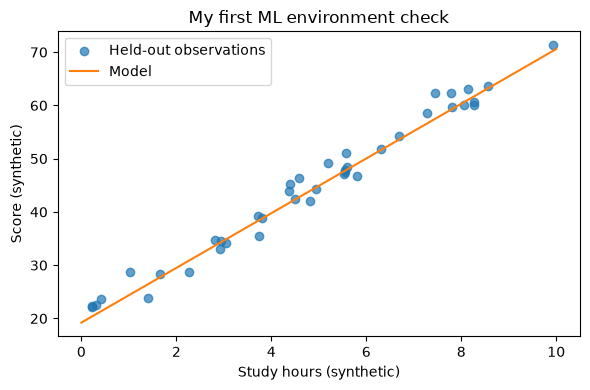

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_test["study_hours"], y_test, label="Held-out observations", alpha=0.7)
line_X = pd.DataFrame({"study_hours": np.linspace(0, 10, 100)})
ax.plot(line_X["study_hours"], model.predict(line_X), color="tab:orange", label="Model")
ax.set(xlabel="Study hours (synthetic)", ylabel="Score (synthetic)", title="My first ML environment check")
ax.legend()
fig.tight_layout()
plt.show()

### Plot the same data with plotnine

plotnine uses a grammar of graphics: start with a data table, map columns to
visual properties with `aes`, then add layers with `+`. This may feel familiar
from ggplot2 in R. Here the points are held-out observations and the line is the
same fitted model used above.

The final `learning_plot` expression displays the plot in a notebook. See the
[plotnine installation guide](https://plotnine.org/guide/install.html).

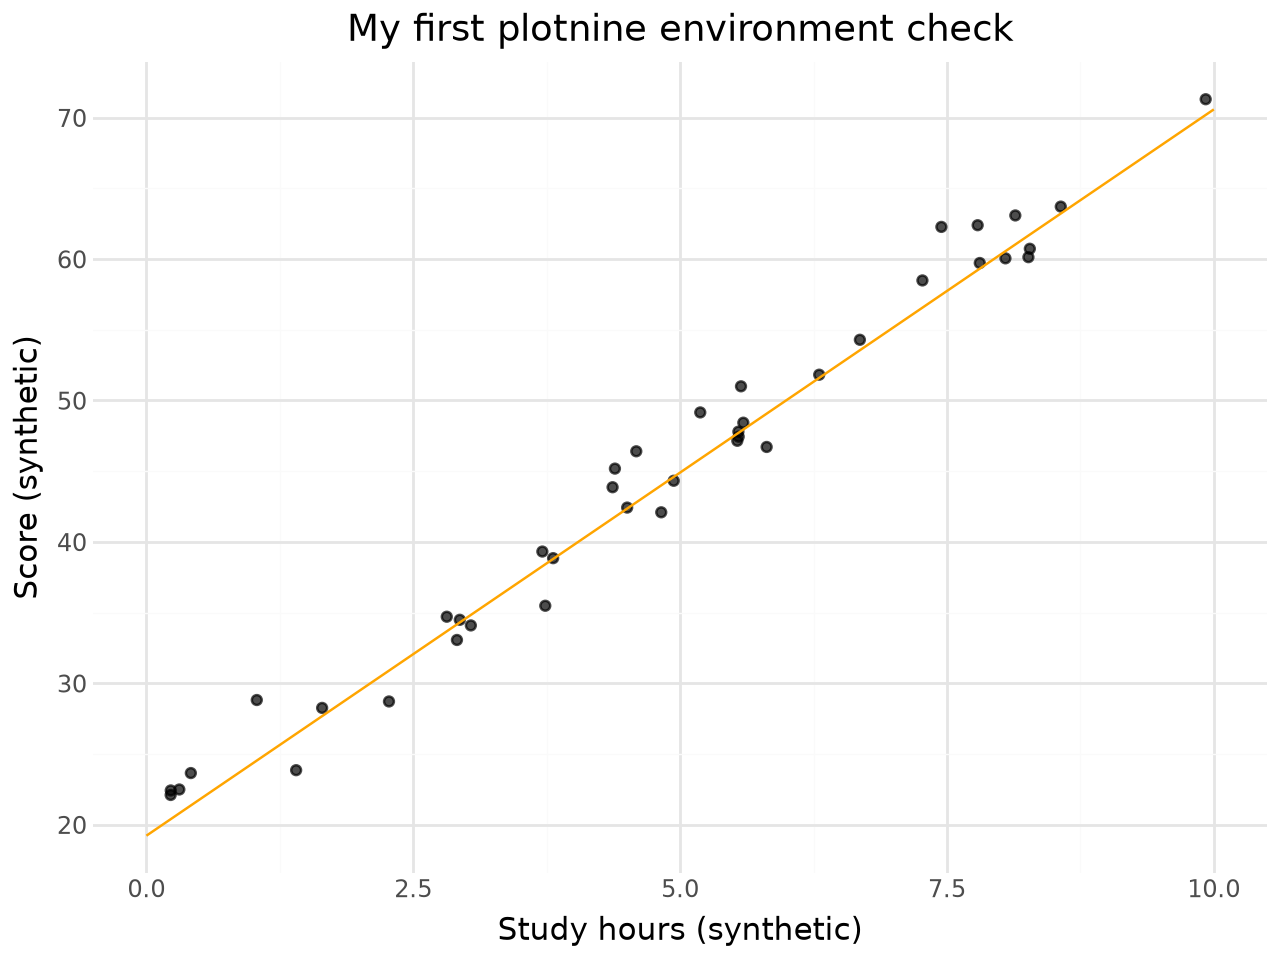

In [10]:
plot_data = X_test.assign(score=y_test)
line_data = line_X.assign(predicted_score=model.predict(line_X))
learning_plot = (
    p9.ggplot(plot_data, p9.aes(x="study_hours", y="score"))
    + p9.geom_point(alpha=0.7)
    + p9.geom_line(
        data=line_data,
        mapping=p9.aes(x="study_hours", y="predicted_score"),
        inherit_aes=False,
        color="orange",
    )
    + p9.labs(
        x="Study hours (synthetic)",
        y="Score (synthetic)",
        title="My first plotnine environment check",
    )
    + p9.theme_minimal()
)
learning_plot

## 7. Smoke test: a tiny TensorFlow/Keras model

A Keras model is a composition of layers. Here one dense layer maps one input
feature to one output. A forward pass checks that Keras can execute, without the
extra time or complexity of training a neural network. Training comes in a later
notebook.

In [11]:
tiny_model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1),
])
inputs = tf.constant([[0.0], [1.0], [2.0]])
outputs = tiny_model(inputs, training=False)
assert tuple(outputs.shape) == (3, 1)
assert bool(tf.reduce_all(tf.math.is_finite(outputs)).numpy())
tiny_model.summary()
print("Forward-pass output:", outputs.numpy().ravel())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

Forward-pass output: [0.        1.2408034 2.4816067]


## 8. Save and reproduce a working setup

After the checks pass, run these commands in the activated terminal from
`Hands-on-ML`. `pip freeze` captures transitive dependencies too; the output file
is a snapshot of this particular Python/platform combination, not a universal lockfile.
Use a descriptive filename and commit it when useful. Rerunning this command
replaces that file.

```bash
python -m pip freeze > requirements-lock.txt
python -m pip check
```

To rebuild on a compatible machine, create a fresh Python 3.13 environment, activate
it, install with 

```bash
python -m pip install -r requirements-lock.txt
```

then register and
select its kernel. On a different OS, start with `requirements.txt` and make a
new snapshot if the old one has platform-specific packages.

Keep source notebooks and dependency files in Git. The local `.gitignore` excludes
`.venv/` and notebook checkpoints. Never put source code inside `.venv/`; environments
are disposable and should be recreated if the project moves.

Use fixed random seeds, record versions, and run **Restart Kernel and Run All**
before saving a finished notebook. Seeds reduce randomness, but exact results can
still vary across hardware, package versions, and TensorFlow operations.

When finished in a terminal, run `deactivate`. Already-running notebook kernels
continue until shut down separately.

## 9. Troubleshooting notes

| Symptom | What I check |
| --- | --- |
| `ModuleNotFoundError` | Print `sys.executable`, choose the project kernel, and install with that environment's Python. The package `scikit-learn` is imported as `sklearn`. |
| `No matching distribution found` | Check Python version, OS/CPU architecture, pip version, and TensorFlow's current support table. Use Python 3.13 for this guide. |
| TensorFlow DLL load error on Windows | Check the Microsoft Visual C++ runtime requirements in the TensorFlow installation guide. |
| Kernel not listed | Rerun kernel registration from `.venv`, refresh/reopen the notebook interface, or select `.venv`'s interpreter directly. |
| Kernel fails after moving the project | Recreate `.venv` and register again; kernel registration stores the interpreter path. |
| GPU list is empty | CPU use is fine here. For GPU work, verify platform support and drivers using the TensorFlow guide. |
| Different results after rerunning cells | Restart the kernel and run all cells in order; check seeds and versions. |

Useful terminal diagnostics:

```bash
python -m pip --version
python -m pip check
python -m jupyter kernelspec list
```

Official references:
[Python venv](https://docs.python.org/3.13/library/venv.html),
[TensorFlow installation and platform requirements](https://www.tensorflow.org/install/pip),
and [IPython kernels](https://ipython.readthedocs.io/en/stable/install/kernel_install.html).

## 10. My learning log

Fill this in after running the notebook:

- **Date / time spent:** 1 hour
- **OS, Python version, and interpreter path:** Ubuntu 22.04, Python 3.13
- **What I learned about environments and kernels:** Create new Jupyter kernels for reuse
- **Errors I encountered and how I fixed them:** None
- **Observed RMSE / R²:**: R² is the coeffcient of determination, gives the percentage of variation explained by the model, and in linear regression, it is the square of correlation coefficient.
- **One question I still have:** None
- **Next experiment:** change the noise level or training size and explain the effect.

For later notebooks, record the question, data source, assumptions, experiment,
results, and takeaway. Explain *why* I chose an approach alongside the code.

**Done when:** the project kernel is selected, all Python cells run from a fresh
kernel, both plotting examples render, TensorFlow's forward pass succeeds, and I have written
at least one learning note.